In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import bioframe
from scipy.stats import chi2_contingency, ttest_ind
from statsmodels.stats.multitest import multipletests
from matplotlib.lines import Line2D

In [2]:
#Fold change columns
cols_dict={'Nipbl_logFC': "NIPBL logFC", 'Rad21_logFC': "RAD21 logFC", 'Mau2_logFC': "MAU2 logFC", 
           'Wapl_logFC': "WAPL logFC", 'Esco1_logFC': "ESCO1 logFC",'Ctcf_logFC': "CTCF logFC",
           'Pds5a_logFC': "PDS5A logFC", 'Pds5b_logFC': "PDS5B logFC",  'Rad21.Nipbl_logFC': "RAD21+NIPBL logFC", 
           'Pds5ab_logFC': "PDS5AB logFC", 'JQ1_logFC': "JQ1 logFC"}
cols_fc = []
for k,v in cols_dict.items():
    cols_fc = cols_fc + [v]

In [3]:
#Load output from E2G_assignment_3.ipynb
E2G_cat = pd.read_table("GSE196450_DE_E2G.txt")
E2G_cat = E2G_cat.rename(columns=cols_dict).rename(columns={"RAD21.NIPBL": "RAD21+NIPBL"})
E2G_cat.head()

,TargetGene,ensembl_id,chromosome,strand,start_gene,end_gene,length,type,RAD21,NIPBL,...,distanceToTSS.Feature,normalizedDNase_prom.Feature,3DContact.Feature,ABC.Score.Feature,numCandidateEnhGene.Feature,numTSSEnhGene.Feature,sumNearbyEnhancers.Feature,ubiquitousExpressedGene.Feature,Score,Category
0,ABCA1,ENSG00000165029,chr9,-,104781005,104928155,147150,protein_coding,-1.0,-1.0,...,63128.5,0.602487,0.043102,0.123664,4,1,120.522916,False,0.918358,Long
1,ABCA13,ENSG00000179869,chr7,+,48171457,48647497,476040,protein_coding,0.0,0.0,...,86344.0,0.337148,0.006644,0.036300,9,2,699.028160,False,0.827642,Long
2,ABCC1,ENSG00000103222,chr16,+,15949576,16143074,193498,protein_coding,-1.0,0.0,...,92684.0,0.387109,0.020855,0.064144,19,1,57.883633,False,0.950571,Long
3,ABCC3,ENSG00000108846,chr17,+,50634880,50692253,57373,protein_coding,-1.0,0.0,...,68753.5,0.319897,0.022720,0.030049,22,1,390.514390,False,0.895215,Long
4,ABL1,ENSG00000097007,chr9,+,130713015,130885683,172668,protein_coding,0.0,0.0,...,122393.5,0.567599,0.028851,0.088303,8,1,313.004625,False,0.888744,Long


In [4]:
#Up/down columns
cols_reg = ['RAD21', 'NIPBL', 'RAD21+NIPBL', 'MAU2', 'WAPL', 'PDS5A',
            'PDS5B', 'PDS5AB', 'ESCO1', 'CTCF', 'JQ1']

In [5]:
palette = ["#67000d", '#e32f27', '#fcc4ad', "grey"]
E2G_cat["Category"] = E2G_cat["Category"].replace("NoEnh", "None")

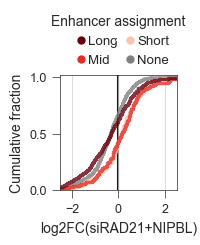

In [6]:
#Plot fold-change categories in Rad21+Nipbl KD
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.5, 1.5), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

df = E2G_cat.copy()
order = ["Long", "Mid", "Short", "None"]


g = sns.ecdfplot(data=df, hue="Category", x="RAD21+NIPBL logFC", lw=2.5, 
                 palette=palette, hue_order=order, alpha=0.8)

g.set(ylim=[0,1.02], xlim=[-2.5,2.5])
g.grid(True, axis="x", linewidth=0.5)
plt.axvline(0, color="k", zorder=-1)
g.set_xlabel("log2FC(siRAD21+NIPBL)", fontsize=10)
g.set_ylabel("Cumulative fraction", fontsize=10)
g.tick_params(labelsize=9)

handles = [
    Line2D([0], [0], marker='o', color='white', 
           markerfacecolor=palette[0], markersize=7, label="Long"),
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[1], markersize=7, label="Mid"),
    Line2D([0], [0], marker='o', color='white', 
           markerfacecolor=palette[2], markersize=7, label="Short"),
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[3], markersize=7, label="None")
]

g.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.97),
    ncol=2,
    title="Enhancer assignment",
    title_fontsize = 10,
    frameon=False,
    handletextpad=-0.5,
    columnspacing=0,
    fontsize=9.5
)


In [7]:
pval = []

#For all conditions compare the fold change of short- vs long-range genes with a t-test
for col in cols_fc:
    x = df.loc[df["Category"] == "Long", col].dropna()
    y = df.loc[df["Category"] == "Short", col].dropna()
    if len(x) > 0 and len(y) > 0:
        tt = ttest_ind(x, y, alternative="two-sided")
        diff = np.mean(x) - np.mean(y)
        pval.append({
            "Perturbation": col,
            "pval": tt.pvalue,
            "n_x": len(x),
            "n_y": len(y),
            "Mean_difference": diff,
        })

pval = pd.DataFrame(pval)

#FDR correction
mh = multipletests(pval["pval"], alpha=0.05, method="fdr_bh")
pval["padj"] = mh[1]
pval["sig"] = mh[0]
pval["log10_p"] = -np.log10(pval["padj"])
pval["Perturbation"] = pval["Perturbation"].str.replace(" logFC", "", regex=False)
pval["Condition"] = pval["Perturbation"] + "_Long vs Short"
pval["N"] = pval["n_x"].astype(str) + "/" + pval["n_y"].astype(str)
pval["test"] = "ttest_ind"
pval.drop(columns=["Perturbation", "n_x", "n_y", "Mean_difference"]).sort_values("padj")

,pval,padj,sig,log10_p,Condition,N,test
8,0.000003,0.000028,True,4.545633,RAD21+NIPBL_Long vs Short,502/145,ttest_ind
0,0.000165,0.000907,True,3.042314,NIPBL_Long vs Short,502/145,ttest_ind
1,0.000504,0.001847,True,2.733546,RAD21_Long vs Short,502/145,ttest_ind
3,0.144289,0.389554,False,0.409432,WAPL_Long vs Short,502/145,ttest_ind
10,0.177070,0.389554,False,0.409432,JQ1_Long vs Short,502/145,ttest_ind
6,0.218866,0.401254,False,0.396580,PDS5A_Long vs Short,502/145,ttest_ind
4,0.302386,0.475178,False,0.323143,ESCO1_Long vs Short,502/145,ttest_ind
5,0.813730,0.895103,False,0.048127,CTCF_Long vs Short,502/145,ttest_ind
7,0.693456,0.895103,False,0.048127,PDS5B_Long vs Short,502/145,ttest_ind
9,0.801111,0.895103,False,0.048127,PDS5AB_Long vs Short,502/145,ttest_ind


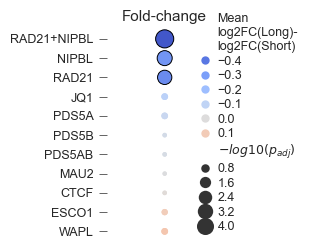

In [8]:
#Plot p-value heatmap for fold-change t-test
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.5, 2.75), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

#Order by directionality
pval["dir_log10"] = np.where(pval["Mean_difference"] < 0, -pval["log10_p"], pval["log10_p"])
pval = pval.sort_values("dir_log10")
data = pval

#First plot with edgecolor annotation for significance
g = sns.scatterplot(
    data=pval,
    y="Perturbation",
    x=[""] * len(pval), 
    size="log10_p",
    hue="Mean_difference",
    palette="coolwarm",
    edgecolor=np.array(pval["sig"].map({True: "black", False: "none"})),
    linewidth=0.7,
    hue_norm=(-.5, .5),
    sizes=(10, 170),
    legend=False
)

plt.xticks([])

#Second plot for legend
g1 = sns.scatterplot(
    data=pval,
    y="Perturbation",
    x=[""] * len(pval),
    size="log10_p",
    color="k",
    zorder=-1,
    hue="Mean_difference",
    palette="coolwarm",
    legend="brief",
    hue_norm=(-0.5,.5),
    linewidth=0,
    sizes=(10, 170),
    ax=None,
)

leg = g1.legend_

handles, labels = g1.get_legend_handles_labels()

labels = [
    "Mean\nlog2FC(Long)-\nlog2FC(Short)" if l == "Mean_difference" else
    r"$-log10(p_{adj})$" if l == "log10_p" else l
    for l in labels
]

g1.legend(
    handles,
    labels,
    bbox_to_anchor=(0.75, 1.1),
    loc="upper left",
    frameon=False,
    fontsize=9,
    labelspacing=0.2,
    handletextpad=0.5,
    borderpad=0.2,
    borderaxespad=0.2,
    handlelength=1.0,
)

plt.title("Fold-change", fontsize=11)
g.set_ylabel("")
g.tick_params(labelsize=9)


sns.despine(bottom=True, left=True)

,pval,N,padj,sig,log10_p,test,Condition
0,4.896444e-27,112/53/337/19/22/162/12/22/111/31/55/736,5.386089e-26,True,25.268727,chi2_contingency,RAD21
3,4.265684e-20,125/44/333/41/16/146/12/10/123/53/64/705,2.346126e-19,True,18.629649,chi2_contingency,MAU2
10,1.141971e-17,90/40/372/24/44/135/18/27/100/35/113/674,4.187226e-17,True,16.378074,chi2_contingency,JQ1
4,1.006474e-16,42/60/400/22/27/154/20/5/120/190/34/598,2.767805e-16,True,15.557865,chi2_contingency,WAPL
6,2.479339e-15,55/51/396/25/30/148/17/17/111/200/29/593,5.454545e-15,True,14.263241,chi2_contingency,PDS5B
7,5.111665e-13,57/41/404/29/20/154/17/12/116/217/28/577,9.371386e-13,True,12.028196,chi2_contingency,PDS5AB
8,2.966514e-11,82/52/368/27/25/151/15/13/117/160/16/646,4.661665e-11,True,10.331459,chi2_contingency,ESCO1
2,8.687651e-11,105/51/346/21/33/149/16/27/102/112/47/663,1.194552e-10,True,9.922795,chi2_contingency,RAD21+NIPBL
5,2.247431e-08,68/56/378/24/24/155/18/22/105/166/35/621,2.746860e-08,True,7.561164,chi2_contingency,PDS5A
1,1.141936e-07,106/39/357/25/22/156/14/17/114/135/27/660,1.256130e-07,True,6.900966,chi2_contingency,NIPBL


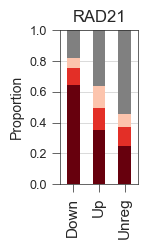

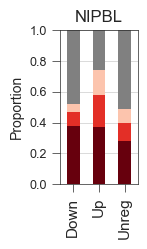

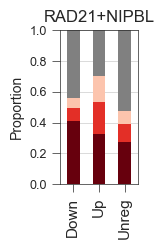

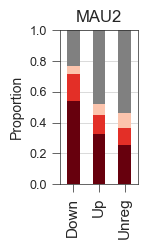

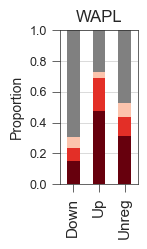

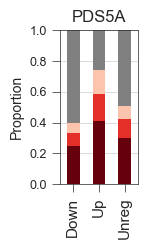

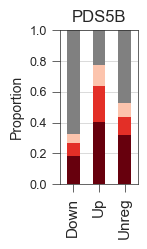

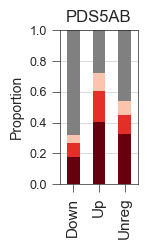

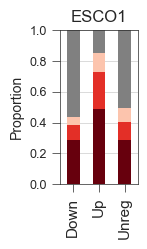

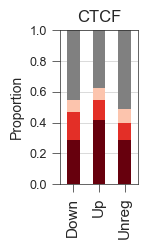

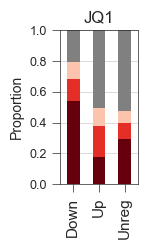

In [9]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.5, 1.5), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

#For each KD, categorise into up/down/unreg and no/short/mid/long-range 
#regulated genes and calculate chi-squared p-value
updowndf = []
df[cols_reg] = df[cols_reg].replace(-1, "Down").replace(1, "Up").replace(0, "Unreg")
for col in cols_reg:
    #Make table
    table = df.set_index("Category")[col].reset_index().groupby(["Category", col],as_index=False).size()
    table[col] = pd.Categorical(table[col], categories=["Down", "Up", "Unreg"], ordered=True)
    table = table.pivot(index=col, columns="Category", values="size")
    order = ["Long", "Mid", "Short", "None"]
    table = table.reindex(index=["Down", "Up", "Unreg"], columns=order, fill_value=0)
    #chi-squared
    chi2, p, dof, expected = chi2_contingency(table)
    #Calculate proportions per category
    table_prop = table.div(table.sum(axis=1), axis=0)
    updowndf.append({
                "Perturbation": col,
                "pval": p,
                "Diff_updown": table_prop.loc["Up", "Long"] - table_prop.loc["Down", "Long"],
                "N": "/".join([x for x in table.melt(var_name="Length",value_name="N")["N"].astype(str).tolist()])
    })
    #Plot
    ax = table_prop.plot(kind="bar", stacked=True, color=palette, 
                         figsize=(1,2), linewidth=0, legend=False)
    ax.set_ylim([0,1])
    plt.ylabel("Proportion")
    plt.title(col)
    plt.xlabel("")
    ax.set_ylabel("Proportion", fontsize=10)
    ax.tick_params(axis="y", labelsize=9)
    handles, labels = ax.get_legend_handles_labels()
    ax.grid(True, axis="y", linewidth=0.5)
updowndf = pd.DataFrame(updowndf)
#Multiple testing correction
mh = multipletests(updowndf["pval"], alpha=0.05, method="fdr_bh")
updowndf["padj"] = mh[1]
updowndf["sig"] = mh[0]
updowndf["log10_p"] = -np.log10(updowndf["padj"])
updowndf["test"] = "chi2_contingency"
updowndf["Condition"] = updowndf["Perturbation"]
updowndf.drop(columns=["Perturbation", "Diff_updown"]).sort_values("padj")

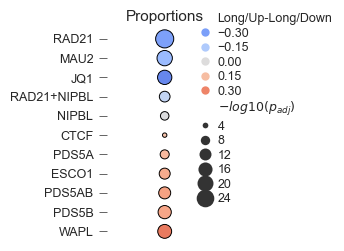

In [10]:
#Plot p-value heatmap for chi-squared test
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.5, 2.75), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

#Order by directionality
updowndf["dir_log10"] = np.where(updowndf["Diff_updown"] < 0, -updowndf["log10_p"], updowndf["log10_p"])
updowndf = updowndf.sort_values("dir_log10")
data = updowndf

#First plot with edgecolor annotation for significance
g = sns.scatterplot(
    data=updowndf,
    y="Perturbation",
    x=[""] * len(updowndf), 
    size="log10_p",
    hue="Diff_updown",
    palette="coolwarm",
    edgecolor=np.array(updowndf["sig"].map({True: "black", False: "none"})),
    linewidth=0.7,
    hue_norm=(-.5, .5),
    sizes=(10, 170),
    legend=False
)

plt.xticks([])

#Second plot for legend
g1 = sns.scatterplot(
    data=updowndf,
    y="Perturbation",
    x=[""] * len(updowndf),
    size="log10_p",
    color="k",
    zorder=-1,
    hue="Diff_updown",
    palette="coolwarm",
    legend="brief",
    hue_norm=(-0.5,.5),
    linewidth=0,
    sizes=(10, 170),
    ax=None,
)

leg = g1.legend_

handles, labels = g1.get_legend_handles_labels()

labels = [
    "Long/Up-Long/Down" if l == "Diff_updown" else
    r"$-log10(p_{adj})$" if l == "log10_p" else l
    for l in labels
]

g1.legend(
    handles,
    labels,
    bbox_to_anchor=(0.75, 1.1),
    loc="upper left",
    frameon=False,
    fontsize=9,
    labelspacing=0.2,
    handletextpad=0.5,
    borderpad=0.2,
    borderaxespad=0.2,
    handlelength=1.0,
)

plt.title("Proportions", fontsize=11)
g.set_ylabel("")
g.tick_params(labelsize=9)


sns.despine(bottom=True, left=True)

In [11]:
#Load merged CTCF peaks (see Nakato_prep_data_1.ipynb)
ctcf = bioframe.read_table("CTCF_RPE1_merged.bed", schema="bed3")

In [12]:
#Find closest CTCF site to each gene in the Long category
long_genes = E2G_cat[E2G_cat["Category"].isin(["Long"])].rename(columns={"start_gene": "start", 
                             "end_gene": "end"})[["TargetGene", "chrom", "start", "end"]+cols_reg]
closest_gene = bioframe.closest(long_genes, ctcf[["chrom", "start", "end"]].drop_duplicates(), k=1, suffixes=["", "_ctcf"]).dropna()

In [13]:
#Find closest CTCF site to each enhancer in the Long category
long_enhancers = E2G_cat[E2G_cat["Category"].isin(["Long"])].rename(columns={"start_enhancer": "start", 
                             "end_enhancer": "end"})[["TargetGene", "chrom", "start", "end"]+cols_reg]
closest_enh = bioframe.closest(long_enhancers, ctcf[["chrom", "start", "end"]].drop_duplicates(), k=1, suffixes=["", "_ctcf"]).dropna()

,pval,N,padj,sig,log10_p,test,Condition
4,0.002098,9/21/159/19/31/198/4/4/17/10/4/26,0.023076,True,1.636835,chi2_contingency,WAPL
7,0.026349,17/16/156/25/24/199/5/1/19/10/0/30,0.144917,False,0.838880,chi2_contingency,PDS5AB
1,0.167709,37/15/137/55/20/173/1/1/23/13/3/24,0.331543,False,0.479460,chi2_contingency,NIPBL
5,0.180688,24/27/138/32/28/188/5/0/20/7/1/32,0.331543,False,0.479460,chi2_contingency,PDS5A
9,0.091399,20/22/147/30/45/173/2/3/20/3/1/36,0.331543,False,0.479460,chi2_contingency,CTCF
10,0.180842,31/13/145/51/20/177/0/4/21/8/3/29,0.331543,False,0.479460,chi2_contingency,JQ1
6,0.232981,21/19/149/21/27/200/5/3/17/8/2/30,0.366113,False,0.436385,chi2_contingency,PDS5B
0,0.384686,39/17/133/57/25/166/4/5/16/12/6/22,0.470172,False,0.327743,chi2_contingency,RAD21
3,0.382130,52/18/119/61/21/166/2/1/22/10/4/26,0.470172,False,0.327743,chi2_contingency,MAU2
2,0.505053,36/17/136/52/26/170/4/4/17/13/4/23,0.555559,False,0.255270,chi2_contingency,RAD21+NIPBL


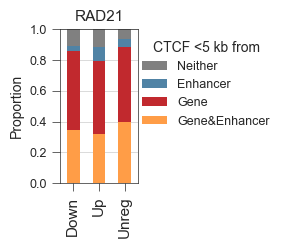

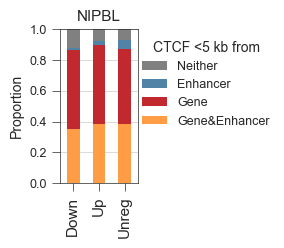

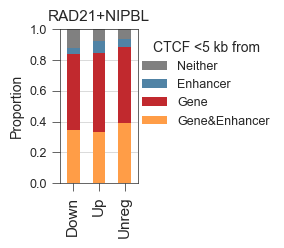

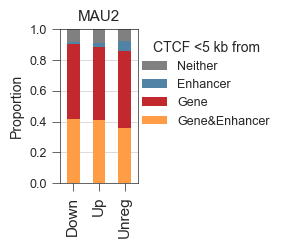

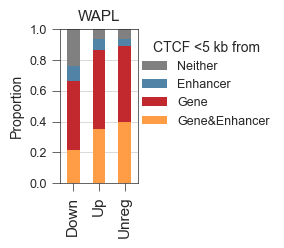

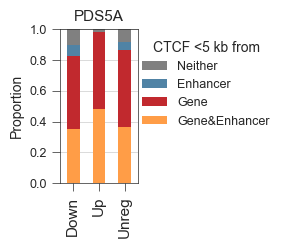

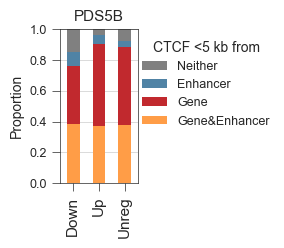

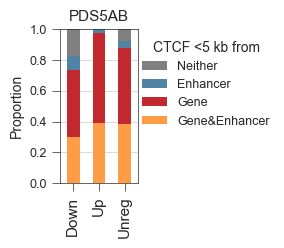

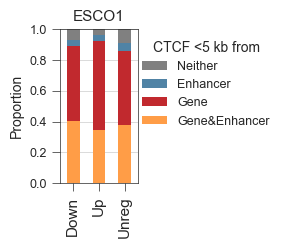

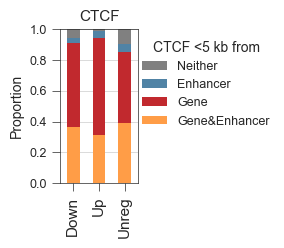

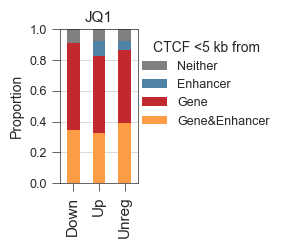

In [14]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.5, 1.5), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

#For each KD, categorise into up/down/unreg and CTCF proximity 
#for long-range regulated genes and calculate chi-squared p-value
ctcfdf = []

#Merge closest enhancer and gene dataframes
ctcf_close = pd.merge(closest_enh, closest_gene, on=["TargetGene", "chrom"], how="left", suffixes=["", "_y"])
#Categorise by <5000bp to nearest
ctcf_close["CTCF_enh"] = np.where(ctcf_close["distance"]<5000, "Enhancer", "")
ctcf_close["CTCF_gene"] = np.where(ctcf_close["distance_y"]<5000, "Gene", "")
ctcf_close["CTCF_near"] = ctcf_close["CTCF_gene"] + ctcf_close["CTCF_enh"]
#Rename
ctcf_close["CTCF_near"] = np.where(ctcf_close["CTCF_near"]=="GeneEnhancer", "Gene&Enhancer", ctcf_close["CTCF_near"])
ctcf_close["CTCF_near"] = np.where(ctcf_close["CTCF_near"]=="", "Neither", ctcf_close["CTCF_near"])
ctcf_close[cols_reg] = ctcf_close[cols_reg].replace(-1, "Down").replace(1, "Up").replace(0, "Unreg")
ctcf_order = ["Gene&Enhancer", "Gene", "Enhancer", "Neither"]

for col in cols_reg:
    #Make table
    table = ctcf_close.groupby(["CTCF_near", col],as_index=False).size()
    table[col] = pd.Categorical(table[col], categories=["Down", "Up", "Unreg"], ordered=True)
    table["CTCF_near"] = pd.Categorical(table["CTCF_near"], categories=ctcf_order, ordered=True)
    table = pd.pivot_table(table, values="size", index=col, columns="CTCF_near", aggfunc="sum", fill_value=0)
    table = table.reindex(columns=ctcf_order, fill_value=0)
    
    #chi-squared
    chi2, p, dof, expected = chi2_contingency(table)
    #Calculate proportions per category
    table_prop = table.div(table.sum(axis=1), axis=0)
    x = 1-float(table_prop.loc["Up", ["Neither"]])
    y = 1-float(table_prop.loc["Down", ["Neither"]])
    ctcfdf.append({
                "Perturbation": col,
                "pval": p,
                "Diff_updown": x-y,
                "N": "/".join([x for x in table.melt(var_name="Length",value_name="N")["N"].astype(str).tolist()])
                
    })
    #Plot
    ax = table_prop.plot(kind="bar", stacked=True, color=['#ff9d47', '#c1292e', '#5083a5',  'grey'], 
                         figsize=(1,2), linewidth=0)
    ax.set_ylim([0,1])
    ax.set_ylabel("Proportion", fontsize=10)
    ax.set_xlabel("")
    plt.title(col, fontsize=11)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(reversed(handles), reversed(labels),
              title="CTCF <5 kb from", bbox_to_anchor=(2.85, 1), loc="upper right", 
              frameon=False, fontsize=9, title_fontsize=10)
    ax.grid(True, axis="y", linewidth=0.5)
    ax.tick_params(axis="y", labelsize=9)

ctcfdf = pd.DataFrame(ctcfdf)
# Multiple testing correction
mh = multipletests(ctcfdf["pval"], alpha=0.05, method="fdr_bh")
ctcfdf["padj"] = mh[1]
ctcfdf["sig"] = mh[0]
ctcfdf["log10_p"] = -np.log10(ctcfdf["padj"])
ctcfdf["test"] = "chi2_contingency"
ctcfdf["Condition"] = ctcfdf["Perturbation"]
ctcfdf.drop(columns=["Perturbation", "Diff_updown"]).sort_values("padj")

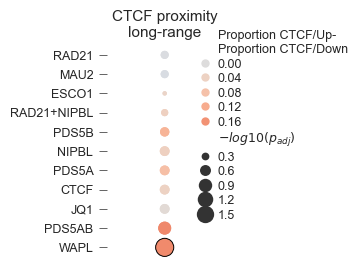

In [15]:
#Plot p-value heatmap for chi-squared test
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.5, 2.75), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

#Order by directionality
ctcfdf["dir_log10"] = np.where(ctcfdf["Diff_updown"] < 0, -ctcfdf["log10_p"], ctcfdf["log10_p"])
ctcfdf = ctcfdf.sort_values("dir_log10")
data = ctcfdf

#First plot with edgecolor annotation for significance
g = sns.scatterplot(
    data=ctcfdf,
    y="Perturbation",
    x=[""] * len(ctcfdf), 
    size="log10_p",
    hue="Diff_updown",
    palette="coolwarm",
    edgecolor=np.array(ctcfdf["sig"].map({True: "black", False: "none"})),
    linewidth=0.7,
    hue_norm=(-.3, .3),
    sizes=(10, 170),
    legend=False
)

plt.xticks([])

#Second plot for legend
g1 = sns.scatterplot(
    data=ctcfdf,
    y="Perturbation",
    x=[""] * len(ctcfdf),
    size="log10_p",
    color="k",
    zorder=-1,
    hue="Diff_updown",
    palette="coolwarm",
    legend="brief",
    hue_norm=(-0.3,.3),
    linewidth=0,
    sizes=(10, 170),
    ax=None,
)

leg = g1.legend_

handles, labels = g1.get_legend_handles_labels()

labels = [
    "Proportion CTCF/Up-\nProportion CTCF/Down" if l == "Diff_updown" else
    r"$-log10(p_{adj})$" if l == "log10_p" else l
    for l in labels
]

g1.legend(
    handles,
    labels,
    bbox_to_anchor=(0.75, 1.1),
    loc="upper left",
    frameon=False,
    fontsize=9,
    labelspacing=0.2,
    handletextpad=0.5,
    borderpad=0.2,
    borderaxespad=0.2,
    handlelength=1.0,
)

plt.title("CTCF proximity\nlong-range", fontsize=11)
g.set_ylabel("")
g.tick_params(labelsize=9)


sns.despine(bottom=True, left=True)